# NIFTY 50 — Exploratory Data Analysis

Exploratory analysis of the cleaned NIFTY 50 price data.
Two key questions answered here:
1. What threshold separates a 'significant' daily move from normal noise?
2. Is the `Volume_Missing` flag concentrated in early years or scattered?


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="darkgrid")

# Robust path: this notebook lives in notebooks/, data lives in
# backend/data/processed/ — so we go up one level then into backend/
DATA_PATH = Path("..") / "backend" / "data" / "processed" / "nifty50_clean.csv"

df = pd.read_csv(DATA_PATH, parse_dates=["Date"])
df = df.set_index("Date")
print(f"Rows: {len(df)}")
print(f"Date range: {df.index.min().date()} to {df.index.max().date()}")
df.head()

Rows: 4654
Date range: 2007-09-17 to 2026-09-04


,Open,High,Low,Close,Volume,Volume_Missing
Date,,,,,,
2007-09-17,4518.450195,4549.049805,4482.850098,4494.649902,0,True
2007-09-18,4494.100098,4551.799805,4481.549805,4546.200195,0,True
2007-09-19,4550.250000,4739.000000,4550.250000,4732.350098,0,True
2007-09-20,4734.850098,4760.850098,4721.149902,4747.549805,0,True
2007-09-21,4752.950195,4855.700195,4733.700195,4837.549805,0,True


## 1. Price trend over time

Full historical Close price from 2007 to present. Key events visible: 2008 financial crisis, 2014-2019 bull run, March 2020 COVID crash, and the subsequent rally to all-time highs.


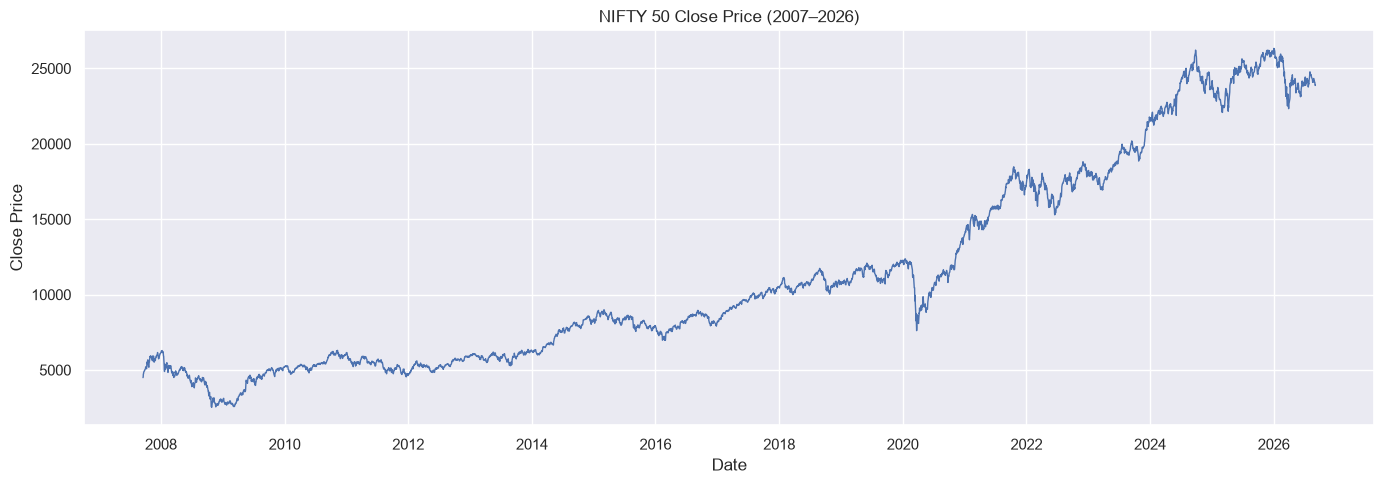

In [2]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Close"], linewidth=1)
plt.title("NIFTY 50 Close Price (2007–2026)")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.tight_layout()
plt.show()

## 2. Daily returns distribution

Percentage change in Close price from one session to the next. The standard deviation here determines the labelling threshold used in feature engineering.


count    4653.000000
mean        0.044288
std         1.293708
min       -12.980466
25%        -0.521497
50%         0.056394
75%         0.651607
max        17.744066
Name: Daily_Return_Pct, dtype: float64


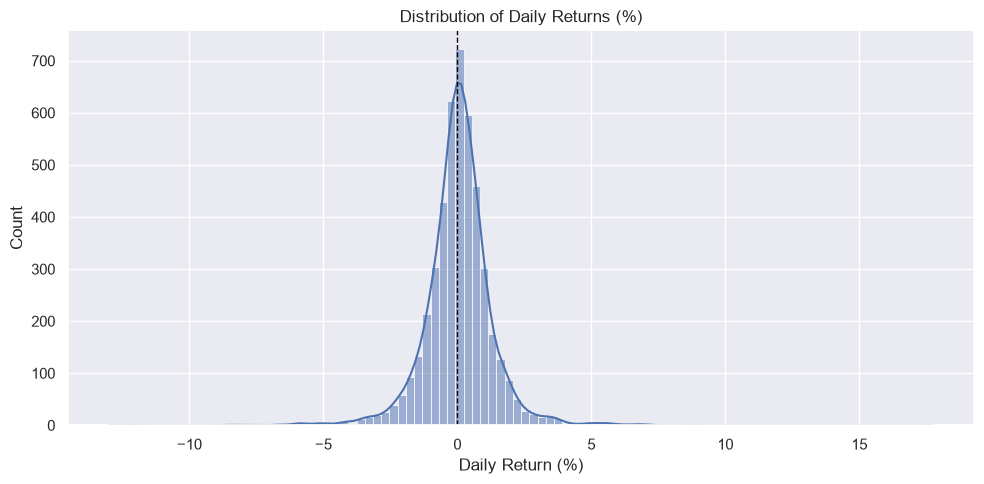

In [3]:
# pct_change() computes (today - yesterday) / yesterday, as a fraction.
# We multiply by 100 to express it as a percentage, which is more
# intuitive to read and set thresholds on.
df["Daily_Return_Pct"] = df["Close"].pct_change() * 100

print(df["Daily_Return_Pct"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df["Daily_Return_Pct"].dropna(), bins=100, kde=True)
plt.title("Distribution of Daily Returns (%)")
plt.xlabel("Daily Return (%)")
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

### Significant move threshold

Moves beyond one standard deviation of daily returns (±1.29%) are labelled as significant (1 or -1). Moves within this band are labelled 0 (no significant move).


In [4]:
std_return = df["Daily_Return_Pct"].std()
print(f"Standard deviation of daily returns: {std_return:.3f}%")
print(f"Suggested 'significant move' threshold (~1 std dev): ±{std_return:.2f}%")

# How often would this actually trigger? Sanity check — if it's too rare
# or too common, we may want to adjust (e.g. use 0.75 std dev or 1.5 std
# dev instead of exactly 1.0).
pct_days_significant = (df["Daily_Return_Pct"].abs() > std_return).mean() * 100
print(f"% of days that would count as 'significant' at this threshold: {pct_days_significant:.1f}%")

Standard deviation of daily returns: 1.294%
Suggested 'significant move' threshold (~1 std dev): ±1.29%
% of days that would count as 'significant' at this threshold: 19.7%


## 3. Rolling volatility

20-day rolling standard deviation of daily returns. Spikes align with known crisis periods (2008, 2020). Used as a model feature to distinguish calm from turbulent market regimes.


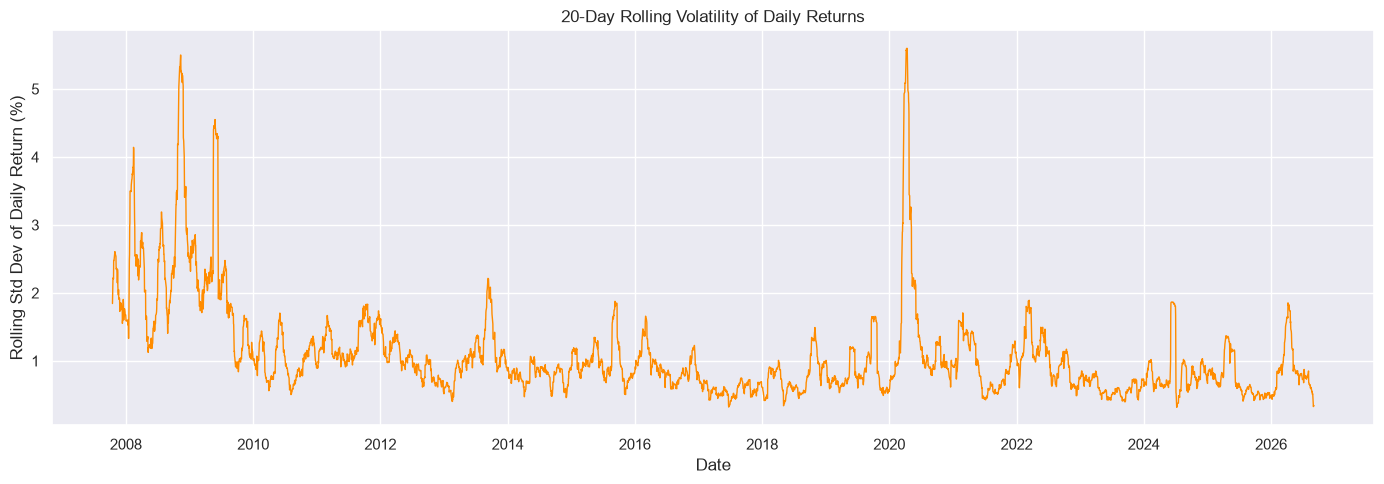

In [5]:
df["Rolling_Volatility_20d"] = df["Daily_Return_Pct"].rolling(window=20).std()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df["Rolling_Volatility_20d"], linewidth=1, color="darkorange")
plt.title("20-Day Rolling Volatility of Daily Returns")
plt.xlabel("Date")
plt.ylabel("Rolling Std Dev of Daily Return (%)")
plt.tight_layout()
plt.show()

## 4. Volume_Missing pattern

Around 28.6% of rows show Volume = 0, flagged during cleaning. This chart checks whether those rows are early-year gaps (expected) or randomly distributed (a data quality concern).


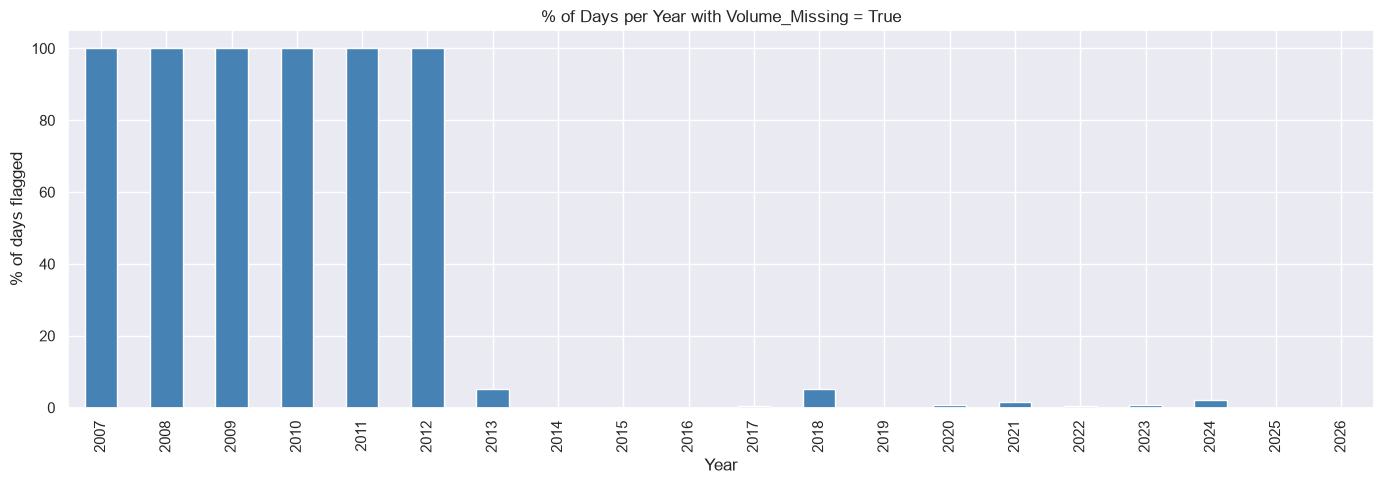

Year
2007    100.000000
2008    100.000000
2009    100.000000
2010    100.000000
2011    100.000000
2012    100.000000
2013      5.263158
2014      0.000000
2015      0.000000
2016      0.000000
2017      0.403226
2018      5.306122
2019      0.000000
2020      0.800000
2021      1.612903
2022      0.403226
2023      0.816327
2024      2.032520
2025      0.000000
2026      0.000000
Name: Volume_Missing, dtype: float64


In [6]:
df["Year"] = df.index.year
missing_by_year = df.groupby("Year")["Volume_Missing"].mean() * 100

plt.figure(figsize=(14, 5))
missing_by_year.plot(kind="bar", color="steelblue")
plt.title("% of Days per Year with Volume_Missing = True")
plt.xlabel("Year")
plt.ylabel("% of days flagged")
plt.tight_layout()
plt.show()

print(missing_by_year)

**Finding:** Volume_Missing rows are concentrated in 2007–2012, confirming a historical recording gap rather than random noise. Volume-based features were excluded from the model to preserve consistency across the full training window.


## 5. Key findings

- **Significant move threshold:** ±1.29% (one standard deviation of daily returns)
- **Volume_Missing:** concentrated in 2007–2012 — historical gap, not a data error
- **Volume features excluded** from model training to avoid inconsistent signals
